# Lezione 6 — Significato e similarità: le macchine capiscono davvero?
**Machine Learning for the Humanities · 16 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/06_significato_similarita_clustering.ipynb)

**Metodi:** similarità del coseno, clustering gerarchico (con un confronto con il k-means).

Quando diciamo che due testi "si somigliano", che cosa intendiamo? Il tema, lo stile, il tono, le parole? Una macchina ha
bisogno di una definizione precisa e misurabile. Oggi ne proviamo una, la **similarità del coseno**, e la usiamo per costruire
un piccolo **motore di ricerca** e un **albero genealogico** delle poesie di Leopardi. Poi la mettiamo in difficoltà.

### Obiettivi di apprendimento
1. spiegare la similarità del coseno tra due vettori di parole;
2. costruire un motore di ricerca per "passi simili";
3. leggere una **matrice di similarità** e un **dendrogramma**;
4. usare il **clustering gerarchico** e confrontarlo con il k-means;
5. riconoscere che cosa sfugge a una similarità basata sulle parole (sinonimi, negazione, ordine, ironia).

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

STOPWORDS = set()
for riga in (DATI / "stopwords_it.txt").read_text(encoding="utf-8").splitlines():
    if not riga.startswith("#"):
        STOPWORDS.update(riga.split())
STOPWORDS = sorted(STOPWORDS)

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def frasi(testo, min_parole=5):
    testo = " ".join(testo.split())
    return [f for f in re.split(r"(?<=[.!?;])\s+", testo) if len(f.split()) >= min_parole]

## 1. La similarità del coseno
Ogni testo è un vettore (una freccia) nello spazio delle parole. Due testi sono simili se le loro frecce **puntano nella
stessa direzione**: il coseno dell'angolo tra le frecce va da 0 (nessuna parola in comune) a 1 (stesse parole nelle stesse proporzioni).
La lunghezza dei testi non conta, solo la direzione.

In [3]:
frasi_prova = ["la felicità è un sogno",
               "il sogno della felicità",
               "la gioia è un sogno",
               "il burattino mangiò tre pere"]
cv = CountVectorizer()
V = cv.fit_transform(frasi_prova)
sim = pd.DataFrame(cosine_similarity(V), index=frasi_prova, columns=range(1, 5)).round(2)
sim

,1,2,3,4
la felicità è un sogno,1.00,0.50,0.75,0.00
il sogno della felicità,0.50,1.00,0.25,0.22
la gioia è un sogno,0.75,0.25,1.00,0.00
il burattino mangiò tre pere,0.00,0.22,0.00,1.00


## 2. Un motore di ricerca per passi simili
Dividiamo tutti i testi in frasi, le trasformiamo in vettori TF-IDF e, data una domanda, restituiamo le frasi più vicine.
È, in piccolo, il principio dei motori di ricerca "classici".

In [4]:
OPERE = {"collodi_pinocchio.txt": "Collodi", "manzoni_promessi_sposi.txt": "Manzoni", "dante_commedia.txt": "Dante",
         "leopardi_canti.txt": "Leopardi", "deledda_dopo_il_divorzio.txt": "Deledda",
         "pirandello_cavallo_nella_luna.txt": "Pirandello", "pirandello_umorismo.txt": "Pirandello (saggio)",
         "digiacomo_novelle_napolitane.txt": "Di Giacomo"}
corpus = pd.DataFrame([{"autore": a, "frase": f} for file, a in OPERE.items() for f in frasi(leggi_testo(file))])
motore = TfidfVectorizer(sublinear_tf=True)
M = motore.fit_transform(corpus["frase"])
print(M.shape[0], "frasi,", M.shape[1], "parole diverse")

def cerca(domanda, n=5):
    punteggi = cosine_similarity(motore.transform([domanda]), M)[0]
    migliori = np.argsort(punteggi)[::-1][:n]
    for i in migliori:
        print(f"{punteggi[i]:.2f}  [{corpus['autore'].iloc[i]}]  {corpus['frase'].iloc[i][:150]}")

30962 frasi, 43927 parole diverse


In [5]:
cerca("la felicità è un sogno che non torna più")

0.41  [Pirandello]  quella era anzi la felicità, la vera felicità raggiunta.
0.39  [Deledda]  Ella diceva: — ma questo è un sogno, questo è un sogno!
0.34  [Pirandello]  oh Dio, era un sogno?
0.34  [Leopardi]  e come un sogno Fu la tua vita.
0.32  [Dante]  poi a la bella donna torna’ il viso.


In [6]:
cerca("ridere per non piangere")

0.49  [Pirandello]  e si mise a piangere.
0.47  [Collodi]  Voleva ridere, voleva piangere, voleva dire un monte di cose;
0.47  [Collodi]  Non mi fate più piangere!
0.46  [Manzoni]  ma non era momento da ridere.
0.43  [Deledda]  ma, cosa strana, invece di ridere si mise a piangere convulsivamente, senza lagrime.


I risultati condividono **parole** con la domanda, non necessariamente il **senso**. Una frase che dice la stessa cosa con
parole diverse (*"la gioia svanisce come un'illusione"*) non verrebbe trovata.

## 3. Una matrice di similarità: le poesie di Leopardi
Calcoliamo la similarità di ogni poesia dei *Canti* con ogni altra. Togliamo le parole funzionali, per guardare il lessico.

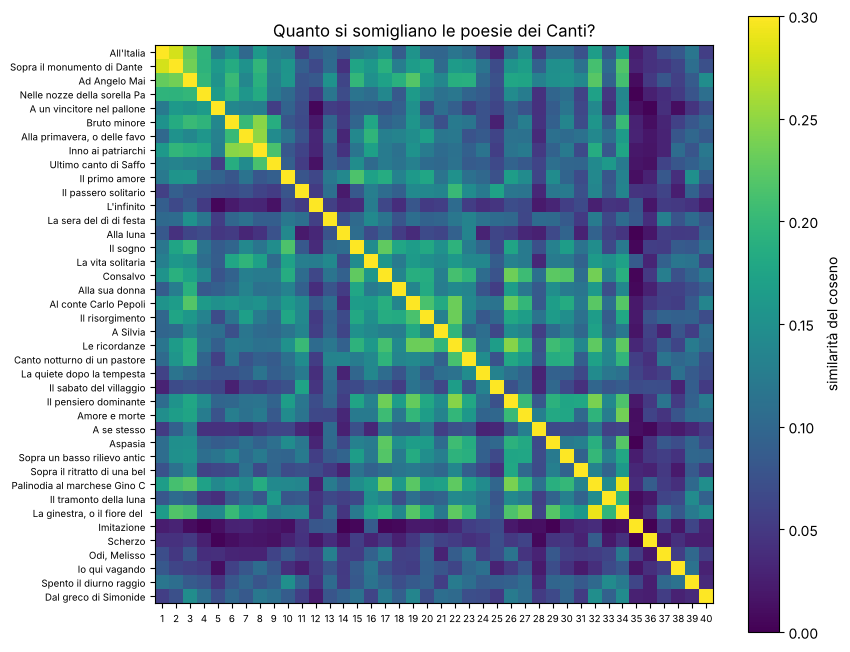

In [7]:
canti = pd.read_csv(DATI / "leopardi_canti.csv")
vett = TfidfVectorizer(stop_words=STOPWORDS, min_df=2, sublinear_tf=True)
X_canti = vett.fit_transform(canti["testo"])
S = cosine_similarity(X_canti)

plt.figure(figsize=(9, 8))
plt.imshow(S, cmap="viridis", vmax=0.3)
plt.colorbar(label="similarità del coseno")
plt.yticks(range(len(canti)), canti["titolo"].str[:28], fontsize=7)
plt.xticks(range(len(canti)), canti["numero"], fontsize=7)
plt.title("Quanto si somigliano le poesie dei Canti?")
plt.show()

In [8]:
np.fill_diagonal(S, 0)
i, j = np.unravel_index(S.argmax(), S.shape)
print("La coppia più simile:", canti["titolo"][i], "↔", canti["titolo"][j], f"({S[i, j]:.2f})")
print("Le poesie più simili a 'Il sabato del villaggio':")
k = canti.index[canti["titolo"] == "Il sabato del villaggio"][0]
for idx in np.argsort(S[k])[::-1][:4]:
    print(f"   {S[k, idx]:.2f}  {canti['titolo'][idx]}")

La coppia più simile: Palinodia al marchese Gino Capponi ↔ La ginestra, o il fiore del deserto (0.29)
Le poesie più simili a 'Il sabato del villaggio':
   0.17  Il passero solitario
   0.17  Le ricordanze
   0.13  La quiete dopo la tempesta
   0.11  Al conte Carlo Pepoli


## 4. Il clustering gerarchico
Il **clustering gerarchico agglomerativo** parte da ogni testo da solo e, passo dopo passo, **unisce i due gruppi più vicini**,
finché non resta un unico gruppo. Il risultato è un **dendrogramma**: un albero in cui l'altezza di ogni unione dice quanto
erano diversi i gruppi uniti. A differenza del k-means:
- non serve scegliere *k* in anticipo: si "taglia" l'albero dopo, all'altezza che si vuole;
- si vede **tutta la storia** delle unioni, non solo il risultato finale.

Il modo di misurare la distanza tra gruppi si chiama **linkage**: `average` (media delle distanze), `complete` (la massima),
`ward` (unisce i gruppi che fanno crescere meno la varianza interna: gruppi compatti ed equilibrati). Con i testi `average`
tende a creare un unico gruppo gigante "a catena"; qui usiamo `ward` (i vettori TF-IDF sono normalizzati, quindi la distanza
euclidea si comporta come il coseno).

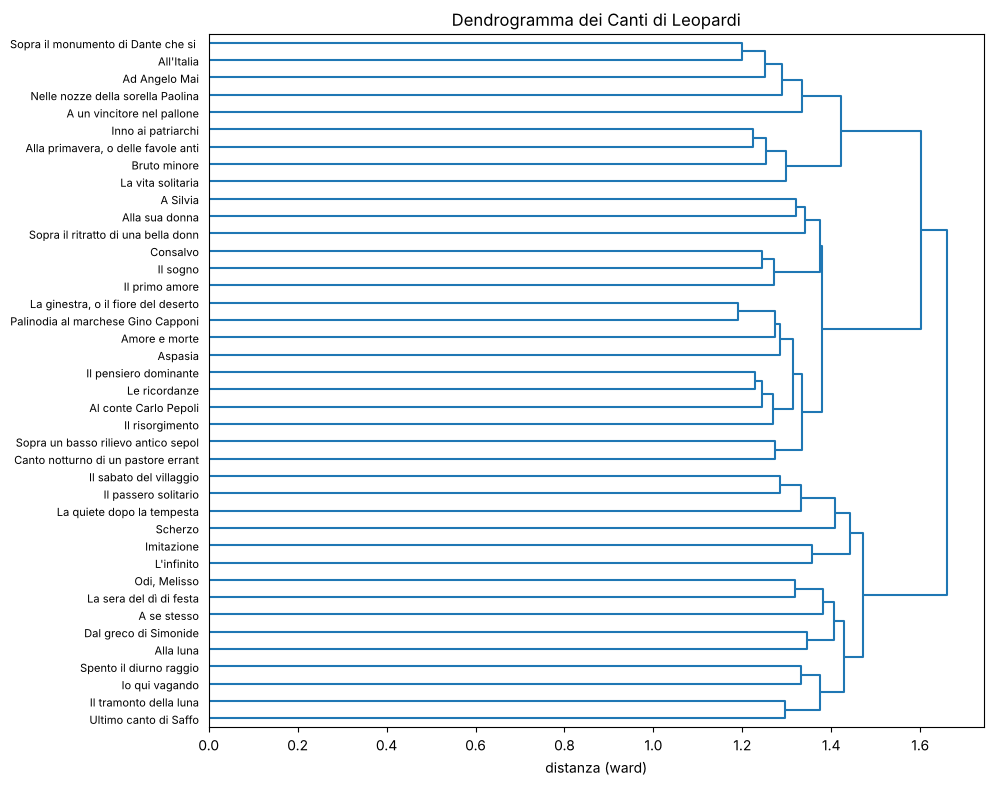

In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_canti.toarray(), method="ward")
plt.figure(figsize=(10, 9))
dendrogram(Z, labels=canti["titolo"].str[:35].tolist(), orientation="right", leaf_font_size=8)
plt.xlabel("distanza (ward)")
plt.title("Dendrogramma dei Canti di Leopardi")
plt.show()

**Come leggerlo.** Due poesie unite molto a sinistra si somigliano molto; unioni sulla destra mettono insieme gruppi diversi.
Cercate le famiglie note alla critica: gli **idilli** (*L'infinito, Alla luna, La sera del dì di festa*), i **canti pisano-recanatesi**
(*A Silvia, Le ricordanze, Il sabato del villaggio, La quiete dopo la tempesta*), le **canzoni civili** iniziali, il **ciclo di Aspasia**.
Il dendrogramma le ritrova? In parte sì (le canzoni civili stanno quasi tutte insieme; *Il passero solitario, La quiete* e
*Il sabato* formano una famiglia), in parte no. Dove non le ritrova, chiediamoci perché: il clustering vede il **lessico**,
la critica guarda anche metro, cronologia, poetica.

In [10]:
canti["gruppo_gerarchico"] = fcluster(Z, t=5, criterion="maxclust")
for g, gruppo in canti.groupby("gruppo_gerarchico"):
    print(f"gruppo {g}:", "; ".join(gruppo["titolo"]))

gruppo 1: Ultimo canto di Saffo; La sera del dì di festa; Alla luna; A se stesso; Il tramonto della luna; Odi, Melisso; Io qui vagando; Spento il diurno raggio; Dal greco di Simonide
gruppo 2: L'infinito; Imitazione
gruppo 3: Il passero solitario; La quiete dopo la tempesta; Il sabato del villaggio; Scherzo
gruppo 4: Il primo amore; Il sogno; Consalvo; Alla sua donna; Al conte Carlo Pepoli; Il risorgimento; A Silvia; Le ricordanze; Canto notturno di un pastore errante dell'Asia; Il pensiero dominante; Amore e morte; Aspasia; Sopra un basso rilievo antico sepolcrale; Sopra il ritratto di una bella donna; Palinodia al marchese Gino Capponi; La ginestra, o il fiore del deserto
gruppo 5: All'Italia; Sopra il monumento di Dante che si preparava in Firenze; Ad Angelo Mai; Nelle nozze della sorella Paolina; A un vincitore nel pallone; Bruto minore; Alla primavera, o delle favole antiche; Inno ai patriarchi; La vita solitaria


### Confronto con il k-means
Con lo stesso numero di gruppi, il k-means trova gli stessi raggruppamenti? Una tabella incrociata ce lo dice.

In [11]:
from sklearn.cluster import KMeans
canti["gruppo_kmeans"] = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(X_canti)
pd.crosstab(canti["gruppo_gerarchico"], canti["gruppo_kmeans"])

gruppo_kmeans,0,1,2,3,4
gruppo_gerarchico,,,,,
1,3,1,3,0,2
2,0,0,1,1,0
3,2,0,0,0,2
4,16,0,0,0,0
5,0,6,3,0,0


I due metodi concordano solo in parte: con 40 testi e un vocabolario poetico ricco, piccole differenze nei dati cambiano i gruppi.
Un clustering è un **punto di vista** sui dati, non una scoperta definitiva.

## 5. Le macchine capiscono davvero? Mettiamo alla prova la similarità

In [12]:
coppie = [
    ("Sono felice.", "Non sono felice."),                               # negazione
    ("Il cane morde l'uomo.", "L'uomo morde il cane."),                  # ordine delle parole
    ("Provava una grande gioia.", "Sentiva una profonda letizia."),      # sinonimi
    ("Che bella giornata!", "Che bella giornata!"),                      # (detto sotto la pioggia: ironia)
]
tutte = [f for c in coppie for f in c]
cv = CountVectorizer(token_pattern=r"(?u)\b\w+\b").fit(tutte)
for a, b in coppie:
    s = cosine_similarity(cv.transform([a]), cv.transform([b]))[0, 0]
    print(f"{s:.2f}   {a!r} ↔ {b!r}")

0.82   'Sono felice.' ↔ 'Non sono felice.'
1.00   "Il cane morde l'uomo." ↔ "L'uomo morde il cane."
0.25   'Provava una grande gioia.' ↔ 'Sentiva una profonda letizia.'
1.00   'Che bella giornata!' ↔ 'Che bella giornata!'


| Caso | Similarità | Che cosa sfugge |
|---|---|---|
| negazione | alta | *non* ribalta il senso, ma è solo una parola in più |
| ordine | **1,00** | il *bag of words* butta via la sintassi: chi morde chi? |
| sinonimi | bassa | *gioia* e *letizia* sono parole diverse, quindi "lontane" |
| ironia | **1,00** | il senso dipende dalla situazione, che non è nel testo |

Una similarità basata sulle parole cattura **la sovrapposizione lessicale**, che spesso (non sempre) accompagna il significato.
Il problema dei sinonimi ha una soluzione parziale: rappresentare le parole in base ai **contesti** in cui compaiono.
È la **semantica distribuzionale**, il tema della prossima lezione.

## Riepilogo
- **Similarità del coseno**: quanto due vettori puntano nella stessa direzione (da 0 a 1).
- **Motore di ricerca**: domanda → vettore → testi più vicini.
- **Clustering gerarchico**: unisce passo dopo passo i gruppi più vicini; il **dendrogramma** mostra la storia delle unioni.
- La similarità lessicale non vede **negazione, ordine, sinonimi, ironia**.

## Esercizi
Soluzioni in `solutions/06_significato_similarita_clustering_soluzioni.ipynb`.

**Esercizio 1 — Un motore di ricerca per la Commedia.** Dividete ogni canto in **terzine** (gruppi di 3 versi) e costruite un
motore di ricerca solo sulle terzine. Cercate *"la luce della gioia eterna"* e un'altra domanda a vostra scelta.
In quale cantica cadono i risultati?

**Esercizio 2 — L'albero di Pinocchio.** Costruite il dendrogramma dei 36 capitoli di *Pinocchio* (etichette: numero e inizio del
titolo). Tagliatelo in 4 gruppi e leggete i titoli di ciascun gruppo: corrispondono a fasi della storia o a qualcos'altro?

**Esercizio 3 — Ingannare la macchina.** Inventate tre coppie di frasi con **similarità alta ma senso diverso** e tre con
**similarità bassa ma senso simile**, possibilmente sulla felicità. Misuratele e commentate.

In [13]:
# Esercizio 1

In [14]:
# Esercizio 2

In [15]:
# Esercizio 3